# 1.Multi Agent

即多智能体协作系统，专门用来处理复杂的任务流程。大多数情况下，使用合适的Tool、合适的提示词和模型，单智能体就能完成任务。我们也推荐大家优先使用单智能体，只有在一些特殊情况下才推荐使用多智能体系统。

## 1.1 使用场景

通常在以下几种情况下我们会使用Multi Agent：
- 上下文管理(Context Management)：如果同时需要调用的工具很多，或者上下文内容很多，我们可以将任务拆分，交给不同的Agent处理
- 分布式开发(Distributed development)：不同的团队独立开发和维护自己的Agent，并将他们组合成一个更大的Agent
- 并行(Parallelization)：将任务拆分为多个子任务，并交给专门的Agent处理，并同时执行它们以加快处理速度
## 1.2 常见模式

多智能体协作的模式有很多种，比较常见的有：
- Subagents：子代理模式，一个主Agent将多个子Agent作为Tool来协调使用。所有请求都由主Agent处理，决定何时以及如何调用每个子Agent
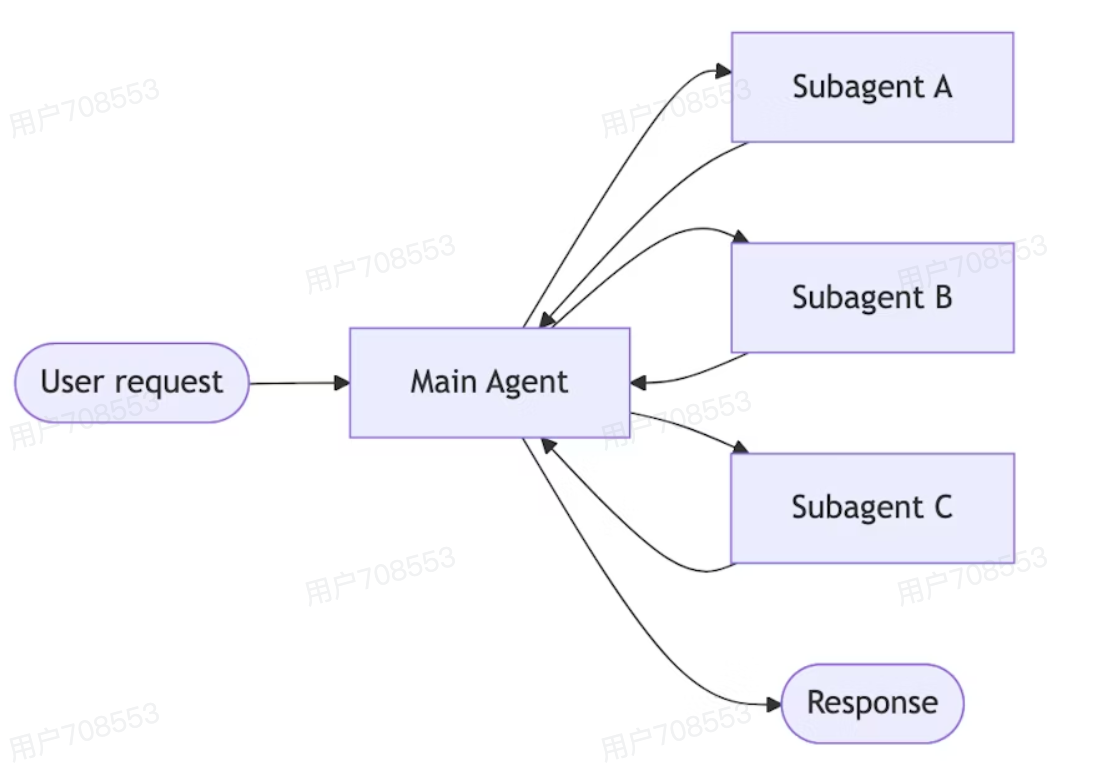
- Handoffs：传递模型，随着任务的执行改变state中的任务状态，从而触发路由变更或者触发Agent的配置变更，从而切换到其它Agent或者改变Agent的工具或系统提示（类似与一个新agent）。因此每个Agent都可以与用户交互，处理用户请求并返回响应。
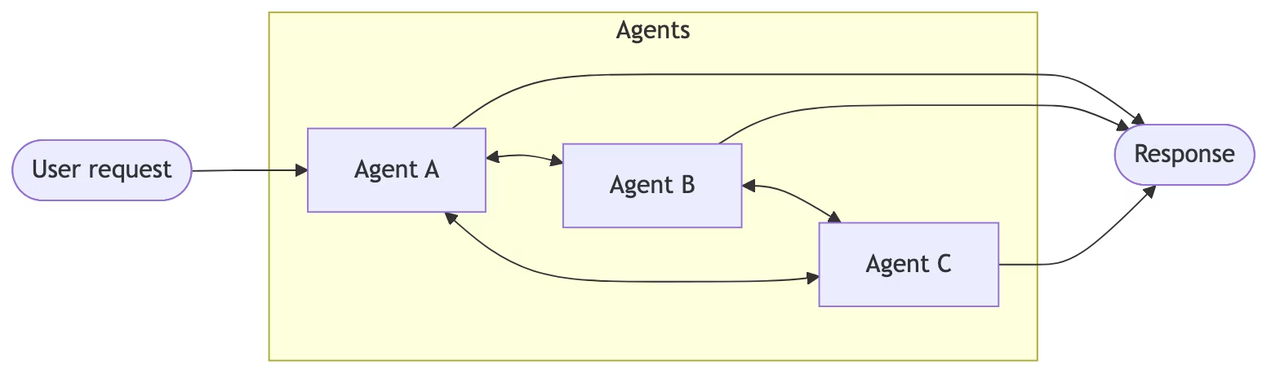
- Skills：技能模式，只有1个Agent，根据任务按需加载Skill或知识
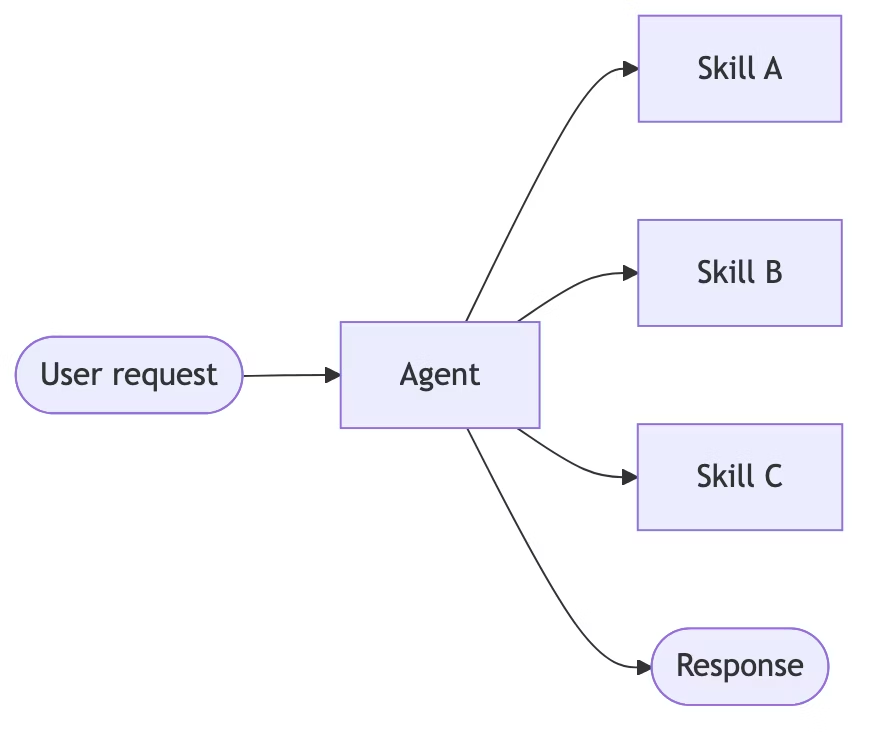
- Router：路由模式，1个负责路由的Agent对用户请求进行分类，将请求导向给一个或多个专门的Agent。最后再由一个Agent负责总结结果。
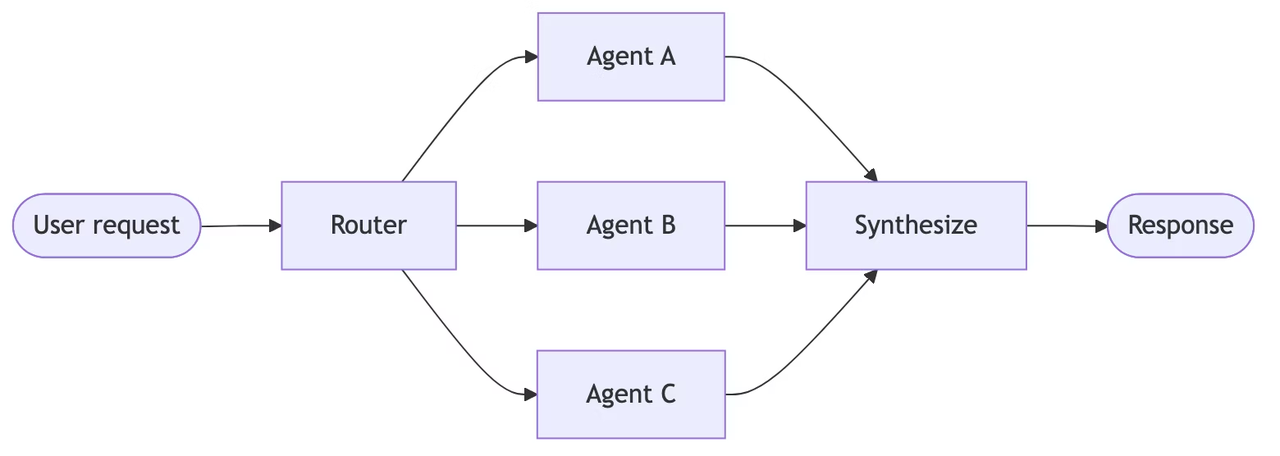

我们从四个方面来对比这几种模式：
- Distributed development：是否支持不同团队独立开发维护
- Parallelization：是否支持并行运行多个subagent
- Multi-hop：是否支持按照特定顺序依次执行多个subagent
- Direct user interaction：是否支持subagent直接与用户对话
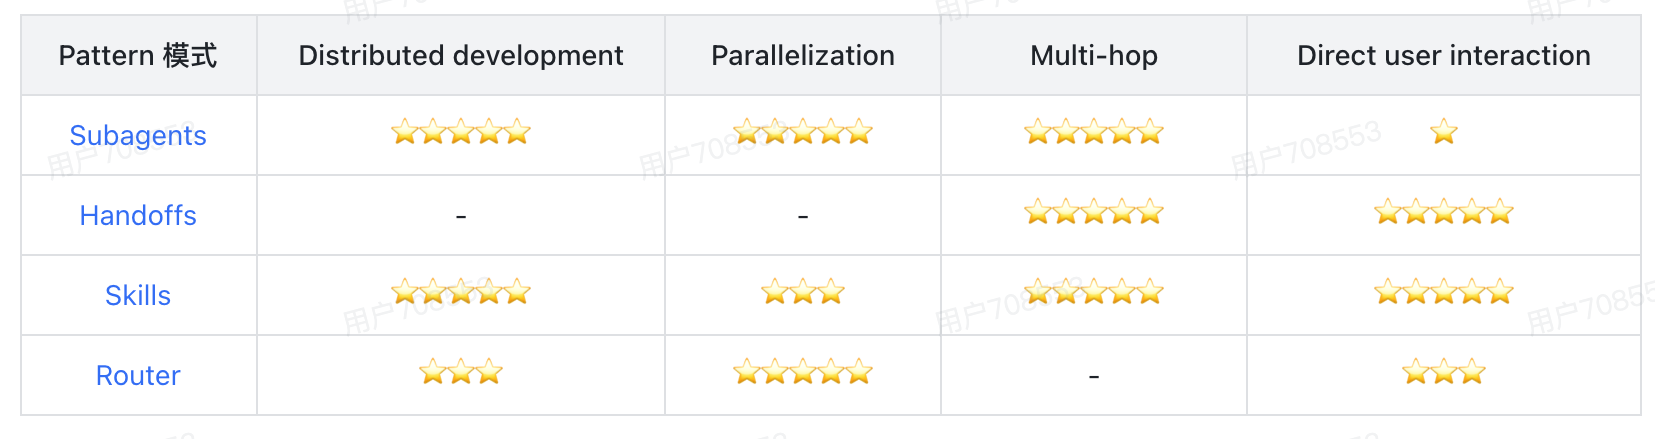

# 2. 案例

接下来，我们就做一个多Agent案例。

现在，我们计划开发一个婚礼策划智能体，它包含以下三个核心功能：
- 旅行规划：负责为你和宾客前往婚礼目的地寻找合适的机票，制定旅行计划
- 场地规划：负责根据宾客人数在目的地寻找合适的婚礼场地
- 音乐规划：负责根据用户需求筛选合适的婚礼歌单，并计算出预算

## 2.1 需求分析

理论上说，我们只要准备好以上每一步所需的工具，写好包含完整流程的系统提示词，用一个Agent就能实现这个功能。

但是，考虑到以下几个原因：
- 要使用的工具实在是太多，航班、场地、音乐等要查询的信息非常多，这会导致单Agent的上下文非常大，有可能超出模型上下文限制。把任务拆解可以减少上下文需求，因此适合分布式开发。
- 旅行、场地、音乐的三个任务没有关联，为了提高效率，可以并行执行

综上，建议采用多Agent开发，模式可以选择Subagents模式。我们可以开发三个Subagent：
- travel agent：负责为你前往婚礼目的地寻找往返机票
- venue agent：负责根据宾客人数在网上搜索合适的婚礼场地
- playlist agent：负责在音乐数据库筛选符合用户需求的歌单，并计算出预算

最后，我们还会定义一个主Agent，负责协调（Coordinator）工作，以及生成最终的婚礼计划方案。

In [1]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_community.utilities import SQLDatabase
from langchain.agents import AgentState
from langchain_tavily import TavilySearch
from langchain.tools import tool
from langchain.tools import ToolRuntime
from langchain.messages import HumanMessage, ToolMessage, AIMessage
from langgraph.types import Command
from langchain.agents import create_agent
from dotenv import load_dotenv

load_dotenv()

True

## 2.2 travel agent
旅行agent要查询机票信息，需要Time和Kiwi两个MCP服务。

In [2]:
# 2.1 创建Subagent旅行
# MCP客户端，包含Time、Kiwi两个MCP
client = MultiServerMCPClient(
    {
        "travel_server": {
                "transport": "http",
                "url": "https://mcp.kiwi.com"
        },
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args": [
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

tools = await client.get_tools()

In [3]:
# Travel agent
travel_agent = create_agent(
    model="deepseek-flash",
    tools=tools,
    system_prompt="""
    你是一个旅行助手Agent。你为用户搜索到达婚礼地点的理想航班，您不能再追问任何后续问题。
    您必须根据以下标准找到最佳航班选择：
    - 价格（最低，经济舱）
    - 持续时间（最短）
    - 日期（您认为在该地点举行婚礼的最佳时间）
    为了使事情变得简单，只寻找一张票，单程。
    你不会得到额外的信息，只有出发地和目的地。你的工作是批判性地思考最佳选择。
    一旦你找到了最好的选项，让用户知道你的候选列表。
    调用搜索航班工具时，如果是地点在中国，需要使用zh-cn作为Locale参数。
    """
)

In [4]:
#测试
response = await travel_agent.ainvoke({"messages": [HumanMessage(content="给我订一张明天从北京到上海的机票")]},
)
for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

给我订一张明天从北京到上海的机票
================================== Ai Message ==================================
Tool Calls:
  get_current_time (call_00_XVchnDJUImUCSXlNH5et6715)
 Call ID: call_00_XVchnDJUImUCSXlNH5et6715
  Args:
    timezone: Asia/Shanghai
================================= Tool Message =================================
Name: get_current_time

[{'type': 'text', 'text': '{\n  "timezone": "Asia/Shanghai",\n  "datetime": "2026-11-12T23:11:20+08:00",\n  "day_of_week": "Thursday",\n  "is_dst": false\n}', 'id': 'lc_78816e23-69f2-467c-8a1f-76a981fc9bc5'}]
================================== Ai Message ==================================
Tool Calls:
  search-flight (call_00_00KWbGZKq4OKAAoGR8oV5776)
 Call ID: call_00_00KWbGZKq4OKAAoGR8oV5776
  Args:
    flyFrom: 北京
    flyTo: 上海
    departureDate: 13/11/2026
    cabinClass: M
    adults: 1
    currency: CNY
    locale: zh-cn
    sort: price
  search-flight (call_

## 2.3 venue agent
接着是负责婚礼场地的agent，这里我们简化实现方案，直接基于tavily搜索场地。

In [5]:
# 定义Tavily web_search工具
web_search = TavilySearch(
    max_results=5,
    topic="general",
)

In [6]:
# 创建 Venue agent
venue_agent = create_agent(
    model="deepseek-flash",
    tools=[web_search],
    system_prompt="""
    你是场地专家，你在指定的位置搜索满足要求的场地。
    你不能再追问任何后续问题，你必须根据以下标准找到最佳的场地选择：
    - 价格（最低）
    - 容量（完全匹配）
    - 评价（最高）
    您可能需要进行多次搜索以迭代地找到最佳选项。
    """
)

In [7]:
#测试
response = await venue_agent.ainvoke({"messages": [HumanMessage(content="上海有哪些合适的可以容纳100人的婚礼场地？")]},
)
for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

上海有哪些合适的可以容纳100人的婚礼场地？
================================== Ai Message ==================================

I'll help you find suitable wedding venues in Shanghai that can accommodate 100 people. Let me search for options.
Tool Calls:
  tavily_search (call_00_sPlG0Ot2TW1FjXnjsz090436)
 Call ID: call_00_sPlG0Ot2TW1FjXnjsz090436
  Args:
    query: 上海 婚礼场地 容纳100人 推荐
    search_depth: advanced
  tavily_search (call_01_MFbnywuGjS0r7sGemsjr4281)
 Call ID: call_01_MFbnywuGjS0r7sGemsjr4281
  Args:
    query: 上海 婚宴酒店 100人 场地 价格 评价
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "上海 婚礼场地 容纳100人 推荐", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.imocona.com/NewsStd_687.html", "title": "上海婚礼的举办场地有哪些？_上海婚礼-上海摩可纳婚礼服务有限公司", "content": "二、举办上海婚礼需要注意什么问题？\n\n上海婚礼的举办地有很多选择，酒店、花园、公园、展览馆等都是不错的


## 2.4 playlist agent
最后，是负责婚礼歌单的agent，为了方便查询，我提供好了一些模拟数据，保存在Sqlite中。db文件在notebooks的resources目录可以找到：

In [8]:
db = SQLDatabase.from_uri("sqlite:///resources/Chinook.db")

@tool
def query_playlist_db(query: str) -> str:

    """Query the database for playlist information"""

    try:
        return db.run(query)
    except Exception as e:
        return f"Error querying database: {e}"

In [9]:
# 测试，查询歌单数据
query_playlist_db.invoke({"query":"SELECT * FROM Playlist"})

"[(1, 'Music'), (2, 'Movies'), (3, 'TV Shows'), (4, 'Audiobooks'), (5, '90’s Music'), (6, 'Audiobooks'), (7, 'Movies'), (8, 'Music'), (9, 'Music Videos'), (10, 'TV Shows'), (11, 'Brazilian Music'), (12, 'Classical'), (13, 'Classical 101 - Deep Cuts'), (14, 'Classical 101 - Next Steps'), (15, 'Classical 101 - The Basics'), (16, 'Grunge'), (17, 'Heavy Metal Classic'), (18, 'On-The-Go 1')]"

In [10]:
# Playlist agent
playlist_agent = create_agent(
    model="deepseek-flash",
    tools=[query_playlist_db],
    system_prompt="""
    你是播放列表专家。查询sql数据库并为给定类型的婚礼策划完美的播放列表。
    一旦你有了你的播放列表，计算播放列表的总时长和成本，每首歌都有一个相关的价格。
    如果在查询数据库时遇到错误，请尝试通过更改查询来修复它们。
    不要空手而归，继续尝试查询数据库，直到你找到一个歌曲列表。
    您可能需要进行多个查询以迭代地找到最佳选项。
    """
)

In [11]:
# 测试
response = await playlist_agent.ainvoke({"messages": [HumanMessage(content="帮我找一个适合婚礼的播放列表，要求包含流行和古典音乐")]},
)
for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

帮我找一个适合婚礼的播放列表，要求包含流行和古典音乐
================================== Ai Message ==================================

我来帮您查找适合婚礼的播放列表，包含流行和古典音乐。首先让我了解一下数据库的结构。
Tool Calls:
  query_playlist_db (call_00_qR65sU2dd6G0EEVe4qJf2011)
 Call ID: call_00_qR65sU2dd6G0EEVe4qJf2011
  Args:
    query: SELECT name, sql FROM sqlite_master WHERE type='table';
================================= Tool Message =================================
Name: query_playlist_db

[('Album', 'CREATE TABLE [Album]\n(\n    [AlbumId] INTEGER  NOT NULL,\n    [Title] NVARCHAR(160)  NOT NULL,\n    [ArtistId] INTEGER  NOT NULL,\n    CONSTRAINT [PK_Album] PRIMARY KEY  ([AlbumId]),\n    FOREIGN KEY ([ArtistId]) REFERENCES [Artist] ([ArtistId]) \n\t\tON DELETE NO ACTION ON UPDATE NO ACTION\n)'), ('Artist', 'CREATE TABLE [Artist]\n(\n    [ArtistId] INTEGER  NOT NULL,\n    [Name] NVARCHAR(120),\n    CONSTRAINT [PK_Artist] PRIMARY KEY  ([ArtistId])\n)'), ('Cust

## 2.5 主Agent
最后，就是主Agent了，也是整个Agent的核心协调者。它负责与用户交互，收集婚礼信息，调用各个Subagent，筹备婚礼计划。

## 2.5.1 定义state
首先，我们需要定义一个state，记录婚礼风格有关的信息，包括：
- 婚礼人数
- 音乐风格
- 出发地
- 婚礼举办地

In [12]:
class WeddingState(AgentState):
    origin: str         # 起点
    destination: str    # 目的地
    guest_count: str    # 宾客数量
    genre: str          # 婚礼风格

## 2.5.2 Tools

首先，要执行婚礼规划任务必须知道婚礼信息，也就是state中要记录的数据。AI通过与用户沟通可以获得这些信息，但是必须有一个tool负责更新state信息，当AI通过与用户聊天获取这些信息后，调用该tool更新到state中。

In [13]:
@tool
def update_state(origin: str, destination: str, guest_count: str, genre: str, runtime: ToolRuntime) -> str:
    """当你询问用户，知道下列所有值时更新State：origin、destination、guest_count、genre"""
    return Command(update={
        "origin": origin,
        "destination": destination,
        "guest_count": guest_count,
        "genre": genre,
        "messages": [ToolMessage("Successfully updated state", tool_call_id=runtime.tool_call_id)]}
        )

接下来，按照Subagent模式，主Agent需要把Subagents当做一个个Tool来协调使用。

所以，我们接下来就先定义3个Tool，分别对应3个Subagent.
这些tool读取state中的婚礼信息，然后调用对应的subagent，分别完成自己的任务。

In [14]:
@tool
async def search_flights(runtime: ToolRuntime) -> str:
    """旅行Agent搜索飞往理想婚礼地点的航班."""
    origin = runtime.state["origin"]
    destination = runtime.state["destination"]

    content = f"查询从{origin}到{destination}的航班"
    response = await travel_agent.ainvoke({"messages": [HumanMessage(content)]})
    return response['messages'][-1].content

@tool
def search_venues(runtime: ToolRuntime) -> str:
    """场地Agent根据给定的地点和宾客数量寻找最佳的婚礼场地."""
    destination = runtime.state["destination"]
    capacity = runtime.state["guest_count"]

    content = f"在{destination}寻找适合{capacity}宾客的婚礼场地"
    response = venue_agent.invoke({"messages": [HumanMessage(content)]})
    return response['messages'][-1].content

@tool
def suggest_playlist(runtime: ToolRuntime) -> str:
    """播放列表Agent根据类型风格策划完美的播放列表."""
    genre = runtime.state["genre"]

    content = f"策划符合{genre}风格的婚礼播放列表的曲目"
    response = playlist_agent.invoke({"messages": [HumanMessage(content)]})
    return response['messages'][-1].content

In [15]:
from langchain.agents import create_agent

coordinator = create_agent(
    model="deepseek-flash",
    tools=[search_flights, search_venues, suggest_playlist, update_state],
    state_schema=WeddingState,
    system_prompt="""
    你是婚礼协调员。你负责与用户沟通，找到更新状态所需的所有信息，并更新到state。
    一旦完成，你就可以委派任务了。将查找航班、搜索场地和策划播放列表的任务委派给您的专家Agent。
    当你收到他们的答案，为我设计一场完美的婚礼方案。
    """
)

In [16]:
response = await coordinator.ainvoke(
    {
        "messages": [HumanMessage(content="我来自北京，我想在上海举办一场100人的婚礼，爵士风格的。")],
    }
)

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

我来自北京，我想在上海举办一场100人的婚礼，爵士风格的。
================================== Ai Message ==================================

太好了！您已经提供了所有必要的信息。让我先更新状态，然后为您委派各项任务。

- **出发地**：北京
- **目的地**：上海
- **宾客人数**：100人
- **风格**：爵士
Tool Calls:
  update_state (call_00_0NxVCDPFr4pqmR7dhKxM0541)
 Call ID: call_00_0NxVCDPFr4pqmR7dhKxM0541
  Args:
    origin: 北京
    destination: 上海
    guest_count: 100
    genre: 爵士
================================= Tool Message =================================
Name: update_state

Successfully updated state
================================== Ai Message ==================================

状态已更新完成！现在我会同时为您委派三个专家任务：查找航班、搜索场地以及策划爵士风格播放列表。
Tool Calls:
  search_flights (call_00_RgzNcYVQg2IEaVzp3vfh9410)
 Call ID: call_00_RgzNcYVQg2IEaVzp3vfh9410
  Args:
  search_venues (call_01_tj1krvQ7IiUVwgnv9Nm48806)
 Call ID: call_01_tj1krvQ7IiUVwgnv9Nm48806
  Args:
  suggest_playlist (call_02_SzvfeOWujbWjsXUtEDdv7682)
 